# EDA 07 · Daily trajectories (motivation for w2)

**Question.** Is there a *temporal* dynamic before churn, beyond the summaries of notebook 06, that justifies a daily sequence model, and how should that model be set up (sequence length, channels, static inputs)?

**Input.** Cleaned daily logs (`C.clean_user_days`) and cleaned transactions (`C.clean_transactions`) of all `fit` customers in the 90-day window (day 0 = 2016-11-03, day 89 = 2017-01-31 = cutoff). Curves are split by the two large subscription states of notebook 03, because the earlier notebooks showed listening means different things in each.

**Plan.**
1. Daily curves of churners vs stayers, aligned to the calendar (cutoff).
2. The same curves aligned to each customer's **expiry date**.
3. Transaction events in the window.
4. When do churners and stayers separate? (per-day and last-k-days discrimination)
5. Does the *shape* of the trajectory add anything beyond the notebook-06 summaries? (weekly vectors in a CV test)
6. Do static member features add on top of everything? (does the LSTM need a static branch?)

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

EDA_DIR = next(p for p in (Path.cwd(), Path.cwd() / "eda") if (p / "_common.py").exists())
sys.path.insert(0, str(EDA_DIR))
import _common as C

pl.Config.set_tbl_rows(40); pl.Config.set_tbl_width_chars(160)
pd.options.display.float_format = "{:,.4f}".format
pd.set_option("display.max_colwidth", None)

users = C.load_fit_population()
BASE = users["is_churn"].mean()
txn = C.clean_transactions(users)
st = C.state_block(C.subscription_state(txn, users))
groups = st.select("msno", "is_churn", "last_expire", "expiry_state",
                   grp=pl.when(pl.col("state").is_in(["auto-renew", "manual"])).then(pl.col("state")).otherwise(pl.lit("other")))
denom = groups.group_by("grp", "is_churn").agg(n=pl.len())
denom

grp,is_churn,n
str,i8,u32
"""other""",1,7353
"""auto-renew""",1,13867
"""auto-renew""",0,633291
"""manual""",1,26384
"""manual""",0,56699
"""other""",0,7105


## 1. Calendar-aligned curves

For every day of the window: share of customers with any listening, and mean `log1p(total_secs)` (0 on silent days), for churners and stayers inside each state. Shaded bands are 95 % intervals.

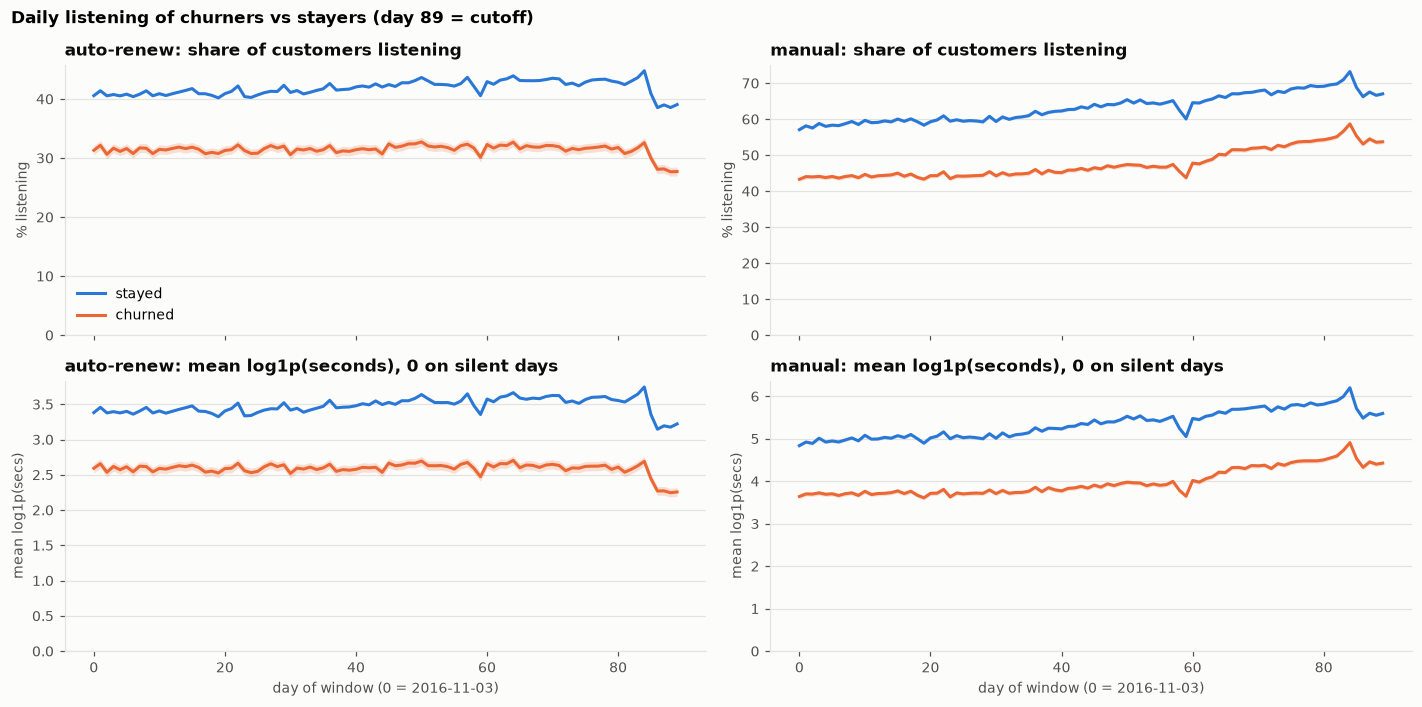

In [2]:
ud = C.clean_user_days(users).join(groups.lazy().select("msno", "is_churn", "grp"), on="msno")
daily = (ud.group_by("day", "grp", "is_churn")
           .agg(active=pl.len(), lsecs=pl.col("total_secs").log1p().sum(), lsecs2=(pl.col("total_secs").log1p() ** 2).sum())
           .collect(engine="streaming")
           .join(denom, on=["grp", "is_churn"])
           .with_columns(active_share=pl.col("active") / pl.col("n"), mean_lsecs=pl.col("lsecs") / pl.col("n"))
           .with_columns(se_lsecs=((pl.col("lsecs2") / pl.col("n") - pl.col("mean_lsecs") ** 2) / pl.col("n")).sqrt())
           .sort("grp", "is_churn", "day"))

def curves(frame, x, title, fname, xlabel):
    fig, axes = plt.subplots(2, 2, figsize=(13, 6.5), sharex=True)
    for j, grp in enumerate(["auto-renew", "manual"]):
        for is_churn, color, label in ((0, C.COLORS["stay"], "stayed"), (1, C.COLORS["churn"], "churned")):
            d = frame.filter((pl.col("grp") == grp) & (pl.col("is_churn") == is_churn)).sort(x).to_pandas()
            lo, hi = C.wilson(d["active"], d["n"])
            axes[0, j].fill_between(d[x], lo * 100, hi * 100, color=color, alpha=0.2, linewidth=0)
            axes[0, j].plot(d[x], d["active_share"] * 100, color=color, linewidth=2, label=label)
            axes[1, j].fill_between(d[x], (d["mean_lsecs"] - 1.96 * d["se_lsecs"]), (d["mean_lsecs"] + 1.96 * d["se_lsecs"]),
                                    color=color, alpha=0.2, linewidth=0)
            axes[1, j].plot(d[x], d["mean_lsecs"], color=color, linewidth=2, label=label)
        axes[0, j].set_title(f"{grp}: share of customers listening", loc="left")
        axes[1, j].set_title(f"{grp}: mean log1p(seconds), 0 on silent days", loc="left")
        axes[0, j].set_ylabel("% listening"); axes[1, j].set_ylabel("mean log1p(secs)")
        axes[1, j].set_xlabel(xlabel); axes[0, j].set_ylim(0, None); axes[1, j].set_ylim(0, None)
    axes[0, 0].legend(frameon=False)
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); C.save_fig(fig, fname); plt.show()

curves(daily, "day", "Daily listening of churners vs stayers (day 89 = cutoff)", "07_calendar_curves", "day of window (0 = 2016-11-03)")

In [3]:
gap = (daily.pivot(index=["grp", "day"], on="is_churn", values="active_share")
            .rename({"0": "stay", "1": "churn"}).with_columns(gap_pp=(pl.col("stay") - pl.col("churn")) * 100))
gap.filter(pl.col("day").is_in([0, 30, 60, 75, 82, 86, 89]) & (pl.col("grp") != "other")).sort("grp", "day")

grp,day,stay,churn,gap_pp
str,i16,f64,f64,f64
"""auto-renew""",0,0.40567,0.313117,9.255227
"""auto-renew""",30,0.411086,0.30569,10.539613
"""auto-renew""",60,0.429488,0.322925,10.656325
"""auto-renew""",75,0.428639,0.316579,11.205972
"""auto-renew""",82,0.430249,0.31117,11.907888
"""auto-renew""",86,0.385442,0.280955,10.448729
"""auto-renew""",89,0.390602,0.277133,11.346966
"""manual""",0,0.570857,0.432914,13.794274
"""manual""",30,0.59352,0.442503,15.101714



- On the calendar the difference between churners and stayers is a **level, not a trajectory**: the gap in the share of customers listening is 9–12 percentage points in the auto-renew group and 13–17 points in the manual group, and it is already there on day 0, three months before the cutoff. Churners do not visibly fade out over the window; they listen less throughout.
- The dips shared by both groups are calendar effects: New Year's Day (day 59) and the Lunar New Year holidays (days 85–89, 27–31 January 2017). Any day-level model sees them as noise common to everyone.
- In the manual group both curves rise over the window, because customers who paid recently are active and the group is defined at the cutoff.


## 2. Curves aligned to the expiry date

The renewal decision happens at the customer's expiry, not at the calendar cutoff. For customers whose current expiry falls in February (89 % of `fit`), day `r` = listening date − expiry date. Each `r` only counts customers whose window covers that day, so the denominator changes with `r`.

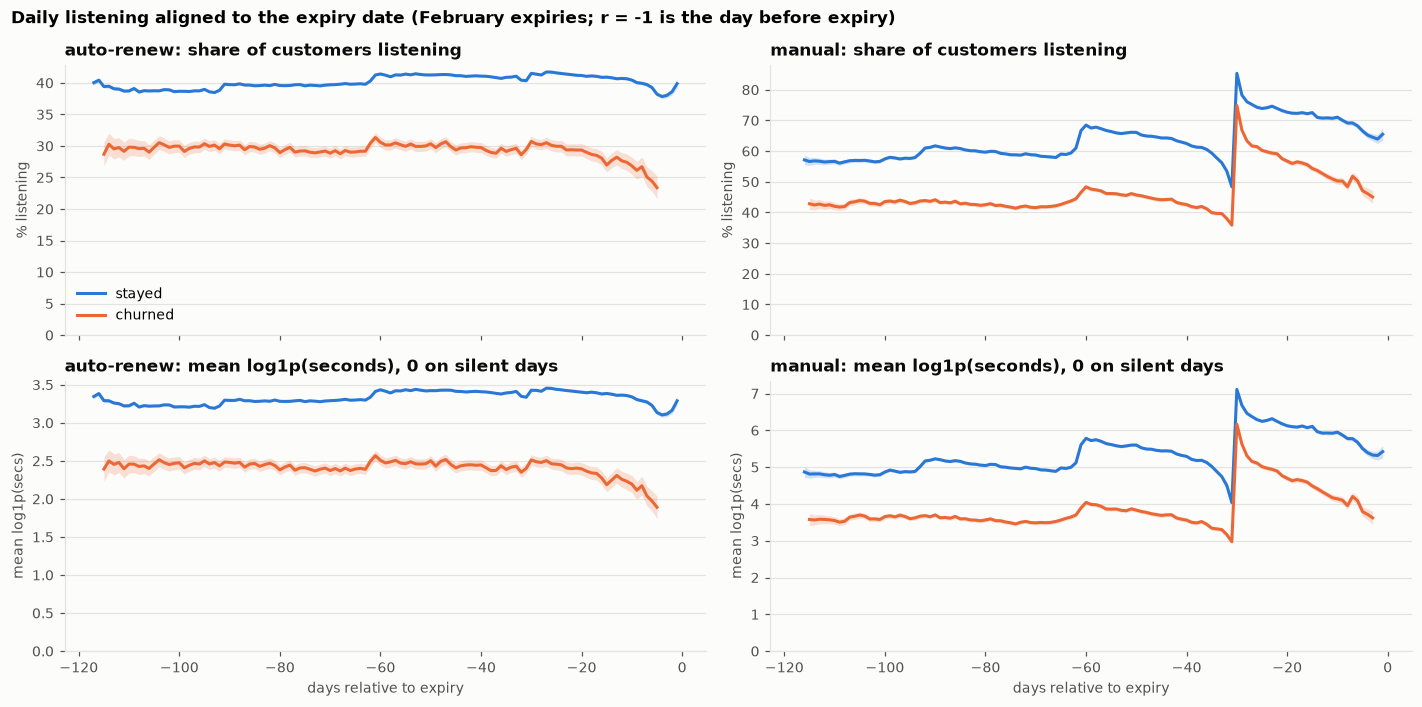

In [4]:
feb = groups.filter(pl.col("expiry_state") == "february").select("msno", "is_churn", "grp", "last_expire")
exp_counts = feb.group_by("grp", "is_churn", "last_expire").agg(n_e=pl.len())
R = np.arange(-117, 0)
cover = []
for r in R:
    lo, hi = C.WINDOW_START - pd.Timedelta(days=int(r)), C.CUTOFF - pd.Timedelta(days=int(r))
    cover.append(exp_counts.filter(pl.col("last_expire").is_between(pl.lit(lo), pl.lit(hi)))
                 .group_by("grp", "is_churn").agg(n=pl.col("n_e").sum()).with_columns(rel=pl.lit(int(r))))
cover = pl.concat(cover)
rel = (C.clean_user_days(users).join(feb.lazy(), on="msno")
         .with_columns(rel=(C.to_date("date") - pl.col("last_expire")).dt.total_days().cast(pl.Int32))
         .group_by("rel", "grp", "is_churn")
         .agg(active=pl.len(), lsecs=pl.col("total_secs").log1p().sum(), lsecs2=(pl.col("total_secs").log1p() ** 2).sum())
         .collect(engine="streaming")
         .join(cover.with_columns(pl.col("rel").cast(pl.Int32)), on=["rel", "grp", "is_churn"])
         .filter(pl.col("n") >= 2000)
         .with_columns(active_share=pl.col("active") / pl.col("n"), mean_lsecs=pl.col("lsecs") / pl.col("n"))
         .with_columns(se_lsecs=((pl.col("lsecs2") / pl.col("n") - pl.col("mean_lsecs") ** 2) / pl.col("n")).sqrt()))
curves(rel, "rel", "Daily listening aligned to the expiry date (February expiries; r = -1 is the day before expiry)",
       "07_expiry_curves", "days relative to expiry")


- Aligned to the expiry date, a real within-cycle dynamic appears:
  - **auto-renew**: stayers stay flat until expiry; churners drift down over the **last ~20 days** (from about 30 % to 23 % listening).
  - **manual**: both groups spike on the day of their last payment, about 30 days before expiry (a monthly plan), and then decay. Churners decay faster and lower (from 75 % to 45 %, against 85 % to 65 % for stayers).
- This dynamic is real, but it is anchored to the **expiry date**. On the calendar axis it is smeared, because February expiries spread over 28 days. A sequence model that only receives calendar days has to infer each customer's position in the billing cycle. Today it gets that only through the transaction state channels.


## 3. Transaction events in the window

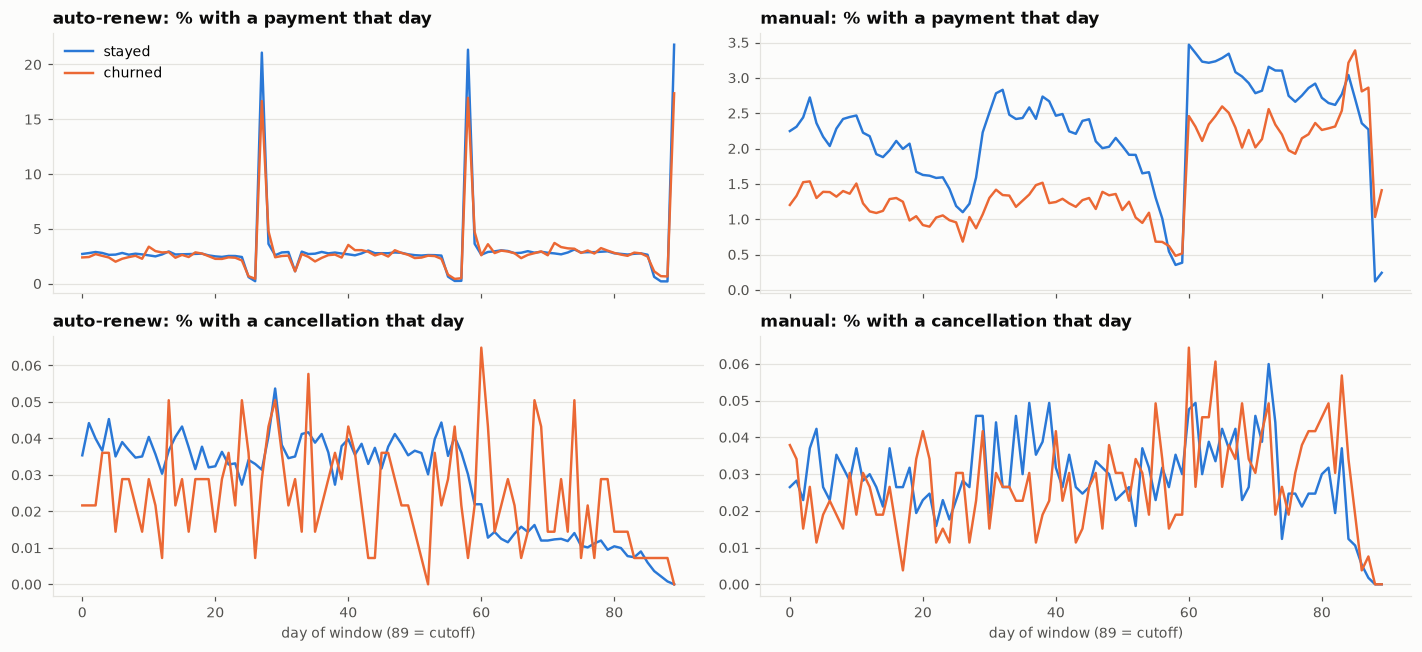

In [5]:
ev = (txn.filter(pl.col("td") >= pl.lit(C.WINDOW_START))
         .with_columns(day=(pl.col("td") - pl.lit(C.WINDOW_START)).dt.total_days())
         .group_by("msno", "day").agg(pay=(pl.col("is_cancel") == 0).any(), cancel=(pl.col("is_cancel") == 1).any())
         .join(groups.select("msno", "is_churn", "grp"), on="msno")
         .group_by("day", "grp", "is_churn").agg(pay=pl.col("pay").sum(), cancel=pl.col("cancel").sum())
         .join(denom, on=["grp", "is_churn"])
         .with_columns(pay_share=pl.col("pay") / pl.col("n"), cancel_share=pl.col("cancel") / pl.col("n")))
fig, axes = plt.subplots(2, 2, figsize=(13, 6), sharex=True)
for j, grp in enumerate(["auto-renew", "manual"]):
    for is_churn, color, label in ((0, C.COLORS["stay"], "stayed"), (1, C.COLORS["churn"], "churned")):
        d = ev.filter((pl.col("grp") == grp) & (pl.col("is_churn") == is_churn)).sort("day").to_pandas()
        axes[0, j].plot(d["day"], d["pay_share"] * 100, color=color, linewidth=1.6, label=label)
        axes[1, j].plot(d["day"], d["cancel_share"] * 100, color=color, linewidth=1.6, label=label)
    axes[0, j].set_title(f"{grp}: % with a payment that day", loc="left")
    axes[1, j].set_title(f"{grp}: % with a cancellation that day", loc="left")
    axes[1, j].set_xlabel("day of window (89 = cutoff)")
axes[0, 0].legend(frameon=False)
fig.tight_layout(); C.save_fig(fig, "07_transaction_events"); plt.show()

In [6]:
def window_events(lo_day):
    e = (txn.filter(pl.col("td") >= pl.lit(C.WINDOW_START + pd.Timedelta(days=lo_day)))
            .group_by("msno").agg(any_pay=(pl.col("is_cancel") == 0).any(), any_cancel=(pl.col("is_cancel") == 1).any()))
    return groups.join(e, on="msno", how="left").with_columns(pl.col("any_pay", "any_cancel").fill_null(False))
e30 = window_events(60)
C.churn_rate_by(e30.filter(pl.col("grp") != "other").with_columns(
    pay=pl.col("any_pay").cast(pl.String), cancel=pl.col("any_cancel").cast(pl.String)), ["grp", "pay", "cancel"])[
    ["grp", "pay", "cancel", "n", "churn_rate"]]

,grp,pay,cancel,n,churn_rate
0,auto-renew,false,false,23902,0.0312
1,auto-renew,true,false,621155,0.0210
2,auto-renew,true,true,2101,0.0405
3,manual,false,false,19387,0.4594
4,manual,true,false,62954,0.2734
5,manual,true,true,742,0.3585



- Auto-renew payments are charged on the **last day of each month** (spikes on days 27, 58, 89 = 30 Nov, 31 Dec, 31 Jan) for churners and stayers alike: the payment calendar carries no churn information inside the auto-renew group.
- Manual churners paid **less often in November–December** than manual stayers (1–1.5 % vs 2–2.8 % per day), which is the history signal of notebook 04 seen day by day.
- Cancellations are very rare per day (≤ 0.06 %) and noisy; as daily events they are too sparse to learn from, which is why the state summary (`state`, `expiry_state`) works better.
- In the last 30 days, a manual customer **without** a payment churns 46 % against 27 % with one.


## 4. When do churners and stayers separate?

Two views, inside each state: (a) ROC AUC of the single-day "listened on day t" flag, for every t; (b) ROC AUC of "active days in the last k days" for growing k.

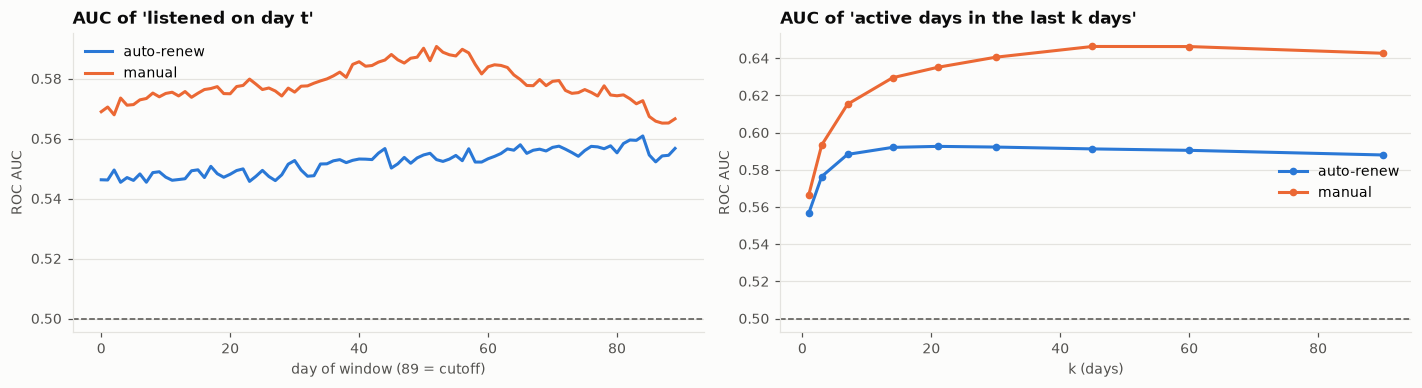

grp,auto-renew,manual
x,,
1,0.5567,0.5666
3,0.5764,0.5933
7,0.5883,0.6153
14,0.5921,0.6295
21,0.5926,0.6351
30,0.5922,0.6406
45,0.5912,0.6463
60,0.5905,0.6463
90,0.5880,0.6427


In [7]:
act = (C.clean_user_days(users).select("msno", "day").collect(engine="streaming"))
lab = groups.filter(pl.col("grp") != "other").select("msno", "is_churn", "grp")
rows = []
for grp in ["auto-renew", "manual"]:
    g = lab.filter(pl.col("grp") == grp)
    y = g["is_churn"].to_numpy()
    idx = {m: i for i, m in enumerate(g["msno"].to_list())}
    a = act.join(g.select("msno"), on="msno")
    mat = np.zeros((g.height, C.WINDOW_DAYS), dtype=np.int8)
    mat[np.fromiter((idx[m] for m in a["msno"]), dtype=np.int64, count=a.height), a["day"].to_numpy()] = 1
    for t in range(C.WINDOW_DAYS):
        rows.append({"grp": grp, "kind": "single day t", "x": t, "auc": roc_auc_score(y, -mat[:, t])})
    for k in (1, 3, 7, 14, 21, 30, 45, 60, 90):
        rows.append({"grp": grp, "kind": "last k days", "x": k, "auc": roc_auc_score(y, -mat[:, -k:].sum(axis=1))})
sep = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for grp, color in (("auto-renew", C.COLORS["stay"]), ("manual", C.COLORS["churn"])):
    d = sep[(sep.grp == grp) & (sep.kind == "single day t")]
    axes[0].plot(d.x, d.auc, color=color, linewidth=2, label=grp)
    d = sep[(sep.grp == grp) & (sep.kind == "last k days")]
    axes[1].plot(d.x, d.auc, color=color, linewidth=2, marker="o", markersize=4, label=grp)
axes[0].set_title("AUC of 'listened on day t'", loc="left"); axes[0].set_xlabel("day of window (89 = cutoff)")
axes[1].set_title("AUC of 'active days in the last k days'", loc="left"); axes[1].set_xlabel("k (days)")
for ax in axes: ax.axhline(0.5, color=C.COLORS["base"], linestyle="--", linewidth=1); ax.set_ylabel("ROC AUC"); ax.legend(frameon=False)
fig.tight_layout(); C.save_fig(fig, "07_separation"); plt.show()
sep[sep.kind == "last k days"].pivot(index="x", columns="grp", values="auc")


- A single day carries little information (AUC 0.55–0.59 for any day t).
- Accumulating days helps up to a point: the AUC of "active days in the last k days" **saturates at about 14–21 days for auto-renew** (0.592) and **about 45 days for manual** (0.646), and the full 90 days is slightly *worse* than 45–60 days.
- So the useful memory is weeks, not months: 60 days covers it with margin; 90 is not wrong, but the oldest month adds mostly noise.


## 5. Does the *shape* of the trajectory add anything?

If a sequence model has something to learn that aggregates miss, a coarse version of the sequence should already help a tree model. Test: the full tabular set built so far (state block, history block, the five listening features of notebook 06) **plus** 13 weekly active-day counts and 13 weekly mean log-seconds (the trajectory at weekly resolution).

In [8]:
weekly = (C.clean_user_days(users).with_columns(week=(pl.col("day") // 7).clip(upper_bound=12))
            .group_by("msno", "week").agg(wa=pl.len(), wl=pl.col("total_secs").log1p().sum())
            .collect(engine="streaming"))
wa = weekly.pivot(index="msno", on="week", values="wa").rename(lambda c: c if c == "msno" else f"wk_active_{int(c):02d}")
wl = weekly.pivot(index="msno", on="week", values="wl").rename(lambda c: c if c == "msno" else f"wk_lsecs_{int(c):02d}")
WEEK = sorted([c for c in wa.columns if c != "msno"]) + sorted([c for c in wl.columns if c != "msno"])
lis = pl.read_parquet(C.CACHE_DIR / "06_listening_features.parquet") if (C.CACHE_DIR / "06_listening_features.parquet").exists() else None
assert lis is not None, "run notebook 06 first (it caches the listening features)"
LISTEN = ["has_logs", "days_since_last_log", "longest_gap", "active_days_30", "secs_30"]
df = (st.join(C.history_block(txn, users), on="msno").join(lis.select(["msno"] + LISTEN), on="msno")
        .join(wa, on="msno", how="left").join(wl, on="msno", how="left")
        .join(C.member_block(users), on="msno")
        .with_columns([pl.col(c).fill_null(0) for c in WEEK]))
data = df.to_pandas(); y = df["is_churn"].to_numpy()
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=C.SEED)

def cv(num, cat):
    pre = ColumnTransformer([("num", "passthrough", list(num)),
                             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), list(cat))])
    model = make_pipeline(pre, HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=C.SEED))
    s = cross_validate(model, data[list(num) + list(cat)], y, cv=CV,
                       scoring=("roc_auc", "average_precision", "neg_log_loss"), n_jobs=5)
    return {"roc_auc": s["test_roc_auc"].mean(), "avg_precision": s["test_average_precision"].mean(),
            "log_loss": -s["test_neg_log_loss"].mean()}

TAB_NUM = C.HISTORY_BLOCK + LISTEN
runs = {
    "state + history + listening (tabular)": (TAB_NUM, C.STATE_BLOCK),
    "+ weekly trajectory (26)": (TAB_NUM + WEEK, C.STATE_BLOCK),
    "+ members": (TAB_NUM + C.MEMBER_NUM, C.STATE_BLOCK + C.MEMBER_CAT),
    "+ weekly trajectory + members": (TAB_NUM + WEEK + C.MEMBER_NUM, C.STATE_BLOCK + C.MEMBER_CAT),
    "trajectory + transaction state only (no history, no members)": (WEEK + ["has_logs"], C.STATE_BLOCK),
}
res = pd.DataFrame({k: cv(*v) for k, v in runs.items()}).T
res

,roc_auc,avg_precision,log_loss
state + history + listening (tabular),0.8997,0.5960,0.1423
+ weekly trajectory (26),0.8994,0.5953,0.1424
+ members,0.9002,0.5973,0.1420
+ weekly trajectory + members,0.9000,0.5969,0.1421
"trajectory + transaction state only (no history, no members)",0.8753,0.5764,0.1480



- **The weekly trajectory adds nothing** on top of the tabular summaries (AP 0.5960 → 0.5953, AUC 0.8997 → 0.8994). The information in the shape of the last 13 weeks is already captured by recency, recent activity and the subscription state.
- Members add a little (+0.0013 AP), consistent with notebook 01: weak next to the subscription state, but not zero.
- The most important row is the last one. With only what a 90-day sequence can contain (the trajectory plus the current subscription state), the model reaches AUC 0.875 / AP 0.576, against 0.900 / 0.597 for the tabular set. The difference is the **history block** (payer tenure, number of payments, lapses since 2015), which lies outside any 90-day window.


## 6. Conclusions


For w2 this notebook gives a clear, partly uncomfortable answer:

1. There is a temporal dynamic, but it is anchored to the **billing cycle** (expiry and payment dates), not to the calendar. Churners differ from stayers mostly by **level** (they listen less all along), and the separable signal lives in the last 2–6 weeks.
2. A coarse version of the sequence adds nothing beyond five recency/activity summaries. A daily model can only win if it learns something finer, and the daily curves do not show such a pattern beyond the expiry-aligned decay.
3. A sequence-only model is capped by what the window contains. It misses the **history** (+0.025 AUC and +0.02 AP here) and the member features. If w2 is to compete with w1, the LSTM needs a **static branch** (history block, member block, state block) concatenated to its final hidden state, and an explicit **days-to-expiry channel** so it can align the sequence to the billing cycle.
4. 60 days is enough sequence length; 90 is acceptable.


In [9]:
decisions = C.write_decisions("07", "Daily trajectories (w2)", [
    {"finding": "Churners listen less throughout the window (gap present from day 0); no calendar-aligned fade-out",
     "decision": "Frame w2 as 'level + recent recency' rather than 'detecting a decline'; report this honestly",
     "kind": "no action"},
    {"finding": "Within-cycle decay is visible only when aligned to the expiry date (auto-renew churners drift down in the last ~20 days)",
     "decision": "Give the LSTM a daily `days_to_expire` channel (already in w2 as `tx_days_to_expire`; keep it, cleaned with the notebook-02/03 rules)",
     "kind": "transformation"},
    {"finding": "Separation saturates at 14-21 days (auto-renew) and ~45 days (manual); 90 days is slightly worse than 45-60",
     "decision": "Sequence length 60 days is enough; keep 90 only if the model is tuned on it (test 60 vs 90 in w2)",
     "kind": "open"},
    {"finding": "Weekly trajectory adds nothing over the 5 tabular listening summaries (AP 0.5960 -> 0.5953)",
     "decision": "Expect little gain from sequences per se; w2 must be compared against w1 with the same information",
     "kind": "no action"},
    {"finding": "A model limited to a 90-day sequence + current state reaches AUC 0.875 vs 0.900 with the history block",
     "decision": "Add a static branch to the LSTM: state block, history block (payer_days, n_payments, n_lapses, total_lapse_days) and member block, concatenated to the final hidden state",
     "kind": "new feature"},
    {"finding": "Auto-renew payments land on month ends for everyone; daily cancellations are too sparse (<= 0.06 %/day)",
     "decision": "Keep transaction channels as state channels (days to expire, auto-renew, cancel state) rather than relying on daily event counts",
     "kind": "transformation"},
    {"finding": "Shared calendar dips (New Year, Lunar New Year 27-31 Jan 2017) affect all customers",
     "decision": "No action; note that the March test window (Dec-Feb) contains the same holidays at different positions",
     "kind": "no action"},
])
decisions

,finding,decision,kind
0,Churners listen less throughout the window (gap present from day 0); no calendar-aligned fade-out,Frame w2 as 'level + recent recency' rather than 'detecting a decline'; report this honestly,no action
1,Within-cycle decay is visible only when aligned to the expiry date (auto-renew churners drift down in the last ~20 days),"Give the LSTM a daily `days_to_expire` channel (already in w2 as `tx_days_to_expire`; keep it, cleaned with the notebook-02/03 rules)",transformation
2,Separation saturates at 14-21 days (auto-renew) and ~45 days (manual); 90 days is slightly worse than 45-60,Sequence length 60 days is enough; keep 90 only if the model is tuned on it (test 60 vs 90 in w2),open
3,Weekly trajectory adds nothing over the 5 tabular listening summaries (AP 0.5960 -> 0.5953),Expect little gain from sequences per se; w2 must be compared against w1 with the same information,no action
4,A model limited to a 90-day sequence + current state reaches AUC 0.875 vs 0.900 with the history block,"Add a static branch to the LSTM: state block, history block (payer_days, n_payments, n_lapses, total_lapse_days) and member block, concatenated to the final hidden state",new feature
5,Auto-renew payments land on month ends for everyone; daily cancellations are too sparse (<= 0.06 %/day),"Keep transaction channels as state channels (days to expire, auto-renew, cancel state) rather than relying on daily event counts",transformation
6,"Shared calendar dips (New Year, Lunar New Year 27-31 Jan 2017) affect all customers",No action; note that the March test window (Dec-Feb) contains the same holidays at different positions,no action


---
**Previous:** `06_user_logs_aggregates.ipynb` · **Next:** `08_integration_and_drift.ipynb`